In [6]:
import json
from pathlib import Path
import pandas as pd

# El notebook se ejecuta desde notebooks/: las rutas se construyen desde la raíz del proyecto
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

def cargar_esios(ruta, columna, zona=None):
    with open(ruta, encoding="utf-8") as f:
        data = json.load(f)
    df = pd.DataFrame(data["indicator"]["values"])
    if zona:
        df = df[df["geo_name"] == zona]
    # Ojo: "datetime_utc" de ESIOS está mal en el cambio de hora de octubre (repite 01:00Z y falta 00:00Z).
    # Se calcula la hora UTC a partir de "datetime", que lleva el desfase de Madrid (+01:00 / +02:00).
    df["hora_utc"] = pd.to_datetime(df["datetime"], utc=True)
    return df[["hora_utc", "value"]].rename(columns={"value": columna})

MES = "2026-10"
precio  = cargar_esios(RAIZ / f"data/raw/esios/precio_{MES}.json", "precio", zona="España")
demanda = cargar_esios(RAIZ / f"data/raw/esios/prevision_demanda_{MES}.json", "demanda_prev")
eolica  = cargar_esios(RAIZ / f"data/raw/esios/prevision_eolica_{MES}.json", "eolica_prev")
solar   = cargar_esios(RAIZ / f"data/raw/esios/prevision_solar_{MES}.json", "solar_prev")

In [7]:
def cargar_openmeteo(ruta, columna):
    # El CSV de Open-Meteo tiene dos bloques separados por una línea en blanco:
    # 1) metadatos de cada punto (lat, lon...)  2) datos horarios: location_id, time, valor
    with open(ruta, encoding="utf-8") as f:
        lineas = f.read().splitlines()
    inicio = lineas.index("") + 1          # primera línea del bloque de datos horarios
    df = pd.read_csv(ruta, skiprows=inicio, encoding="utf-8")
    df.columns = ["punto", "hora_utc", "valor"]
    df["hora_utc"] = pd.to_datetime(df["hora_utc"], utc=True)   # el CSV ya viene en GMT
    # media de todos los puntos en cada hora
    return df.groupby("hora_utc", as_index=False)["valor"].mean().rename(columns={"valor": columna})

temp      = cargar_openmeteo(RAIZ / "data/raw/open-meteo-temperatura.csv", "temp_media")
viento    = cargar_openmeteo(RAIZ / "data/raw/open-meteo-eolica.csv", "viento_medio")
radiacion = cargar_openmeteo(RAIZ / "data/raw/open-meteo-solar.csv", "radiacion_media")

In [8]:
from functools import reduce

tablas = [precio, demanda, eolica, solar, temp, viento, radiacion]
df = reduce(lambda a, b: a.merge(b, on="hora_utc", how="left"), tablas)
df = df.sort_values("hora_utc").reset_index(drop=True)

print(df.shape)   # debería dar (744, 8)
df.head()

(744, 8)


,hora_utc,precio,demanda_prev,eolica_prev,solar_prev,temp_media,viento_medio,radiacion_media
0,2026-10-01 00:00:00+00:00,183.4075,23692.00,3379.50,0.0,20.12,8.525,0.0
1,2026-10-01 01:00:00+00:00,184.7750,23310.75,3692.75,0.0,19.72,11.100,0.0
2,2026-10-01 02:00:00+00:00,179.4250,23006.50,3994.75,0.0,19.42,14.125,0.0
3,2026-10-01 03:00:00+00:00,174.0425,23440.50,4216.75,0.0,19.06,15.800,0.0
4,2026-10-01 04:00:00+00:00,194.7325,26013.50,4413.75,0.0,18.74,15.575,0.0


In [9]:
print("Filas:", len(df), "(esperado 744)")
print("Horas duplicadas:", df["hora_utc"].duplicated().sum())

esperadas = pd.date_range("2026-10-01", "2026-10-31 23:00", freq="h", tz="UTC")
faltan = esperadas.difference(df["hora_utc"])
print("Horas que faltan:", len(faltan))

print("\nNulos por columna:")
print(df.isna().sum())

print("\nPrecios <= 0:", (df["precio"] <= 0).sum())
print("Viento negativo:", (df["viento_medio"] < 0).sum())
noche = df["hora_utc"].dt.hour.isin([0, 1, 2, 3, 4])
print("Radiación > 0 de noche:", (df.loc[noche, "radiacion_media"] > 0).sum())

df.describe()

Filas: 744 (esperado 744)
Horas duplicadas: 0
Horas que faltan: 0

Nulos por columna:
hora_utc           0
precio             0
demanda_prev       0
eolica_prev        0
solar_prev         0
temp_media         0
viento_medio       0
radiacion_media    0
dtype: int64

Precios <= 0: 29
Viento negativo: 0
Radiación > 0 de noche: 0


,precio,demanda_prev,eolica_prev,solar_prev,temp_media,viento_medio,radiacion_media
count,744.000000,744.000000,744.000000,744.000000,744.000000,744.000000,744.000000
mean,166.636169,27223.198925,5288.105847,7850.137433,17.287043,15.019926,170.446573
std,82.250823,4555.948236,3442.442793,9939.728892,3.705918,5.569382,231.756442
min,-1.460000,18333.000000,741.750000,0.000000,8.900000,3.825000,0.000000
25%,118.676250,22926.625000,2587.125000,0.000000,14.300000,10.950000,0.000000
50%,191.780000,27407.375000,4311.125000,108.125000,17.420000,14.337500,1.000000
75%,224.319375,31540.187500,7450.625000,17700.312500,19.920000,18.256250,352.250000
max,319.450000,35157.250000,15661.500000,28345.750000,25.460000,30.075000,736.250000


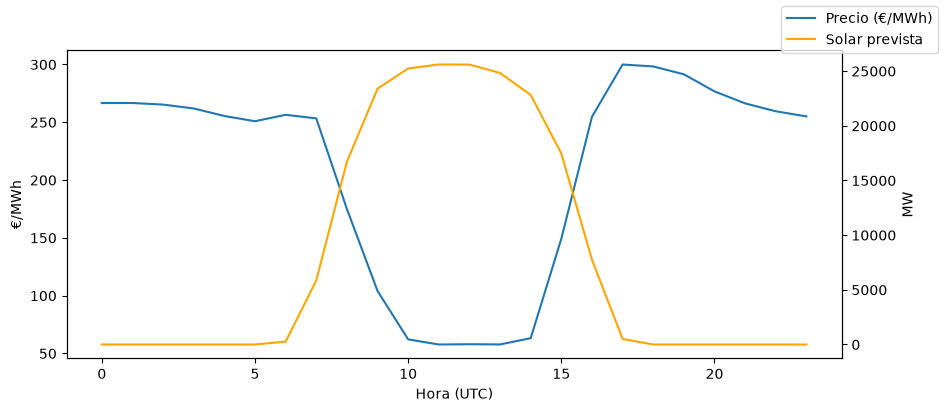

solar_prev        -0.748001
radiacion_media   -0.726228
temp_media        -0.285173
eolica_prev       -0.171983
demanda_prev      -0.164670
viento_medio      -0.133154
precio             1.000000
Name: precio, dtype: float64

In [10]:
import matplotlib.pyplot as plt

# Un día: precio frente a solar prevista (la curva de pato)
dia = df[df["hora_utc"].dt.date == pd.Timestamp("2026-10-31").date()]
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(dia["hora_utc"].dt.hour, dia["precio"], label="Precio (€/MWh)")
ax2 = ax1.twinx()
ax2.plot(dia["hora_utc"].dt.hour, dia["solar_prev"], color="orange", label="Solar prevista")
ax1.set_xlabel("Hora (UTC)")
ax1.set_ylabel("€/MWh")
ax2.set_ylabel("MW")
fig.legend()
plt.show()

# Correlación de cada variable con el precio
df.drop(columns="hora_utc").corr()["precio"].sort_values()

In [11]:
from pathlib import Path
(RAIZ / "data/clean").mkdir(parents=True, exist_ok=True)
df.to_parquet(RAIZ / f"data/clean/dataset_{MES}.parquet", index=False)